# Neural networks: from manual gradients to transfer learning

**Dilhan W.A. · 230145E · EN3160 Assignment 3**

**Repository:** https://github.com/ahesh-dilhan/en3160-assignment-03

This notebook presents three full-data experiments, with the implementation, recorded learning curves, confusion matrices, and interpretation of the final models.

In [1]:
import os, sys, json, math
from pathlib import Path
ROOT = Path.cwd()
for candidate in [ROOT, ROOT.parent, ROOT/'assignment3']:
    if (candidate/'src'/'models.py').is_file() and (candidate/'results').is_dir():
        ROOT = candidate.resolve()
        break
else:
    raise FileNotFoundError('Open this notebook from the Assignment 3 repository.')
sys.path.insert(0, str(ROOT))
os.environ['MPLCONFIGDIR'] = str(ROOT/'tmp'/'matplotlib')
import torch
from torch import nn
from IPython.display import display, Image, Markdown
from src.models import ManualMLP, LeNet5, ModernCNN
from src.experiments import cifar, mnist, transfer
RUN_TRAINING = False  # True repeats full training; False reads completed runs.
def summary(name):
    return json.loads((ROOT/'results'/name/'summary.json').read_text())
def refresh_figures(stage):
    from scripts import make_figures as figures
    if stage == 'q1':
        figures.curves(['cifar_manual'], ['Manual MLP'], 'test', 'q1_curves')
    elif stage == 'q2':
        figures.curves(['lenet5','modern_cnn'], ['LeNet-5','Modern CNN'], 'test', 'q2_curves')
        figures.matrices(['lenet5','modern_cnn'], ['LeNet-5: test counts','Modern CNN: test counts'], list(range(10)), 'q2_confusion')
        figures.mnist_errors()
    elif stage == 'q3':
        figures.curves(['resnet18_finetune','resnet18_features'], ['Fine-tuning','Fixed features'], 'validation', 'q3_curves')
        figures.matrices(['resnet18_finetune','resnet18_features'], ['Fine-tuning: validation counts','Fixed features: validation counts'], ['ants','bees'], 'q3_confusion')
        figures.transfer_examples()
def result_table(names, labels, split='test'):
    lines=['| Model | Epochs | Train loss | Train accuracy | '+split.title()+' loss | '+split.title()+' accuracy |',
           '|---|---:|---:|---:|---:|---:|']
    for name,label in zip(names,labels):
        s=summary(name); tr=s['train']; te=s[split]
        lines.append(f"| {label} | {s['final_epoch']} | {tr['loss']:.4f} | {100*tr['accuracy']:.2f}% | {te['loss']:.4f} | {100*te['accuracy']:.2f}% |")
    display(Markdown('\n'.join(lines)))

## Experimental protocol

All runs use seed **230145** and the complete standard splits: CIFAR-10 50,000/10,000;
MNIST 60,000/10,000; Hymenoptera 244/153 train/validation. Neither CIFAR-10 nor MNIST
is subsampled. The reported training metrics are measured after each epoch, with
dropout disabled and batch normalization in evaluation mode. They are not the
running averages of training minibatches.

The final scheduled checkpoint is reported for every model: epoch 10 for Questions
1–2 and epoch 25 for Question 3. Curves on held-out data are plotted as requested,
but they are not used to tune the settings or choose checkpoints. This is a single
fixed-seed comparison, not a claim of statistical significance.

In [2]:
s=summary('lenet5')
print('Recorded runtime:', s['environment'])

Recorded runtime: {'torch': '2.6.0+cu124', 'torchvision': '0.21.0+cu124', 'numpy': '2.5.4', 'device': 'NVIDIA GeForce RTX 2050', 'cuda': '12.4', 'seed': 230145, 'threads': 6}


In [3]:
audit=json.loads((ROOT/'results'/'data_audit.json').read_text())
for name, data in audit.items():
    print(name, '| exact pixel hashes shared across official splits:', data['exact_pixel_hashes_shared_between_splits'])

CIFAR10 | exact pixel hashes shared across official splits: 0
MNIST | exact pixel hashes shared across official splits: 0
Hymenoptera | exact pixel hashes shared across official splits: 0


Input checks verify image shapes, uint8 ranges, class counts, readable insect images, and exact pixel hashes across the official splits. Exact matches are reported transparently; the specified standard splits are retained unchanged. CIFAR-10 uses the byte-identical MIT Open Learning archive mirror, pinned to a revision and checked against the canonical archive MD5, because the original host was unreachable during preparation.

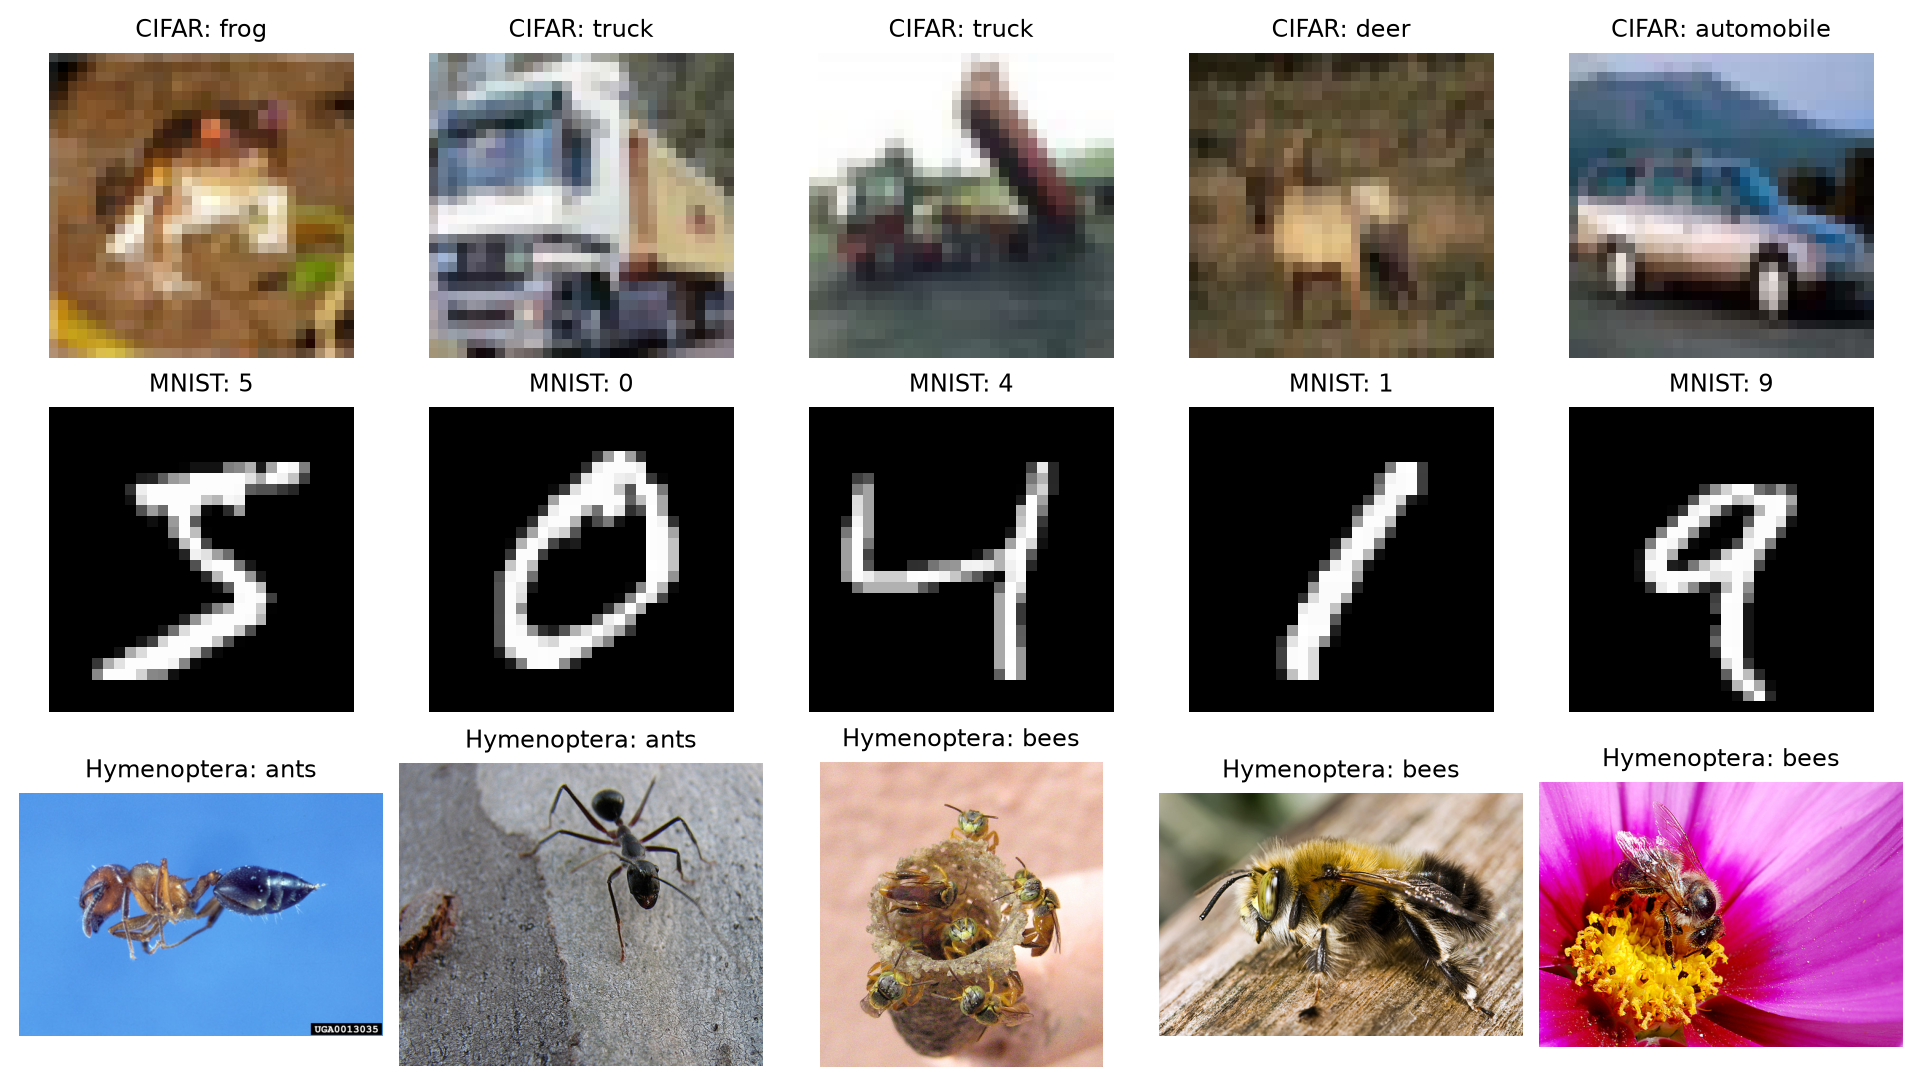

In [4]:
display(Image(filename=str(ROOT/'results'/'figures'/'dataset_examples.png')))

*Figure 1. Actual training images from the three datasets. Natural image colours are preserved; MNIST is originally grayscale.*

<!-- pagebreak -->

## 1. CIFAR-10 with manually computed backpropagation

### Architecture and loss

A normalized RGB image is flattened to $x\in\mathbb{R}^{3072}$. The new hidden layer
contains exactly 100 sigmoid units, followed by ten output logits:

$$H=\sigma(XW_1+b_1),\qquad Z=HW_2+b_2.$$

For batch size $N$, the numerically stable mean cross-entropy is

$$L=-\frac{1}{N}\sum_{i=1}^{N}\left[Z_{i,y_i}-\operatorname{logsumexp}_k Z_{ik}\right].$$

Let $P=\operatorname{softmax}(Z)$ and $Y$ be one-hot targets. The analytic gradients are

$$G=(P-Y)/N,\quad \nabla W_2=H^T G,\quad \nabla b_2=\sum_i G_i,$$
$$D=(GW_2^T)\odot H\odot(1-H),\quad \nabla W_1=X^T D,\quad \nabla b_1=\sum_i D_i.$$

All four gradients are calculated before either weight matrix is updated. Training
uses tensor operations and manual SGD, without `backward()`, `torch.optim`, or
autograd. Autograd is used only as an independent gradient oracle in a small unit test.

In [5]:
def loss_and_gradients(self, x, y):
    logits, h = self.forward(x)
    log_prob = logits - torch.logsumexp(logits, dim=1, keepdim=True)
    loss = -log_prob[torch.arange(len(y), device=y.device), y].mean()
    dz = log_prob.exp()
    dz[torch.arange(len(y), device=y.device), y] -= 1
    dz /= len(y)
    dw2, db2 = h.T @ dz, dz.sum(0)
    dh = (dz @ self.w2.T) * h * (1 - h)
    dw1, db1 = x.T @ dh, dh.sum(0)
    return loss, [dw1, db1, dw2, db2]

### Training settings and implementation choices

The supplied listing's CIFAR-10 normalization, batch size **50**, zero regularization,
and epoch decay **0.9** are retained. There are **10 epochs**. The initial learning
rate is **0.1** and the weights use fan-in normal initialization. These two settings
replace the listing's `2e-6` learning rate and `1e-5` weight standard deviation,
which are poorly scaled for a new sigmoid/mean-cross-entropy model. This is a
disclosed implementation choice; no claim is made that those original settings
would produce the same results.

For every batch, `ManualMLP.step` applies `parameter -= learning_rate * gradient`.
The sigmoid derivative is evaluated from its cached activation, and log-sum-exp
prevents overflow when computing the loss.

In [6]:
if RUN_TRAINING:
    cifar(torch.device('cuda' if torch.cuda.is_available() else 'cpu'))
    refresh_figures('q1')
else:
    print('Using the completed full-data, 10-epoch manual-gradient run.')
result_table(['cifar_manual'], ['Manual sigmoid MLP'])

Using the completed full-data, 10-epoch manual-gradient run.


| Model | Epochs | Train loss | Train accuracy | Test loss | Test accuracy |
|---|---:|---:|---:|---:|---:|
| Manual sigmoid MLP | 10 | 1.3728 | 53.13% | 1.5060 | 47.77% |

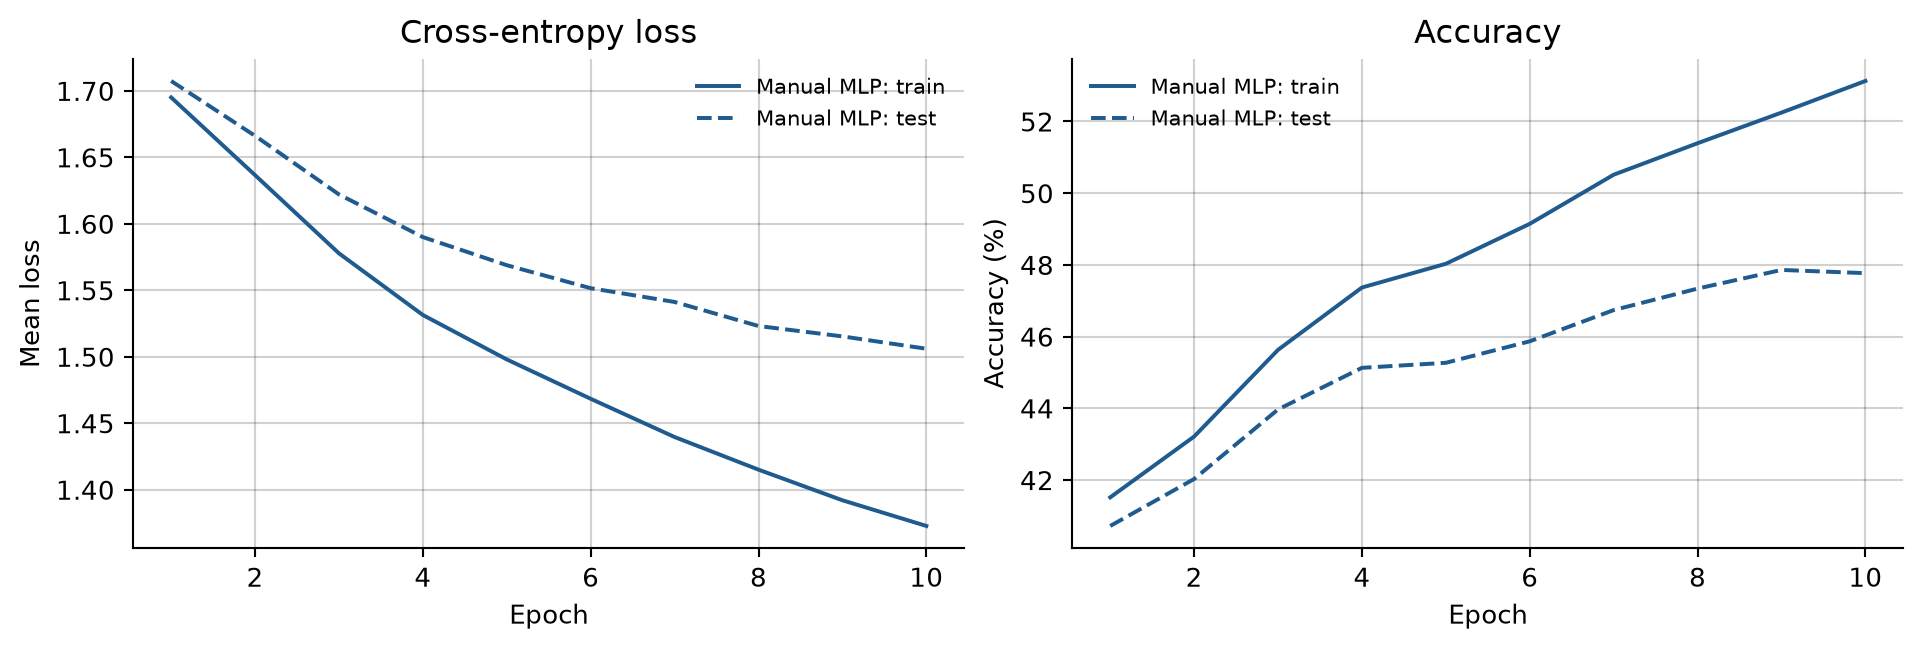

In [7]:
display(Image(filename=str(ROOT/'results'/'figures'/'q1_curves.png')))

*Figure 2. Full training and test splits evaluated after each of the ten epochs; mean cross-entropy and accuracy.*

In [8]:
s=summary('cifar_manual')
display(Markdown(
    f"**Interpretation.** The final network classifies {s['test']['correct']:,} of "
    f"{s['test']['count']:,} test images correctly. The train–test accuracy gap is "
    f"{100*(s['train']['accuracy']-s['test']['accuracy']):.2f} percentage points. "
    "A flattened dense model has no convolutional locality or translation-sharing bias. "
    "Its ten-epoch result demonstrates the requested manual optimization, while leaving "
    "substantial classification error on visually varied natural images. A lower training "
    "loss by itself does not establish better generalization."
))

**Interpretation.** The final network classifies 4,777 of 10,000 test images correctly. The train–test accuracy gap is 5.36 percentage points. A flattened dense model has no convolutional locality or translation-sharing bias. Its ten-epoch result demonstrates the requested manual optimization, while leaving substantial classification error on visually varied natural images. A lower training loss by itself does not establish better generalization.

## 2. MNIST: LeNet-5 and a modern three-layer CNN

### Networks

**LeNet-5:** normalized MNIST is padded from 28×28 to 32×32. The path is
Conv(1→6, 5×5) → tanh → average pool(2) → Conv(6→16, 5×5) → tanh → average
pool(2) → 400→120→84→10. The 400→120 dense layer is equivalent to a 5×5
convolution on the 16×5×5 feature maps. The historical RBF output is replaced with
ten linear logits and cross-entropy, a standard classification adaptation.

In [9]:
class LeNet5(nn.Module):
    """32x32 padded MNIST, tanh and average pooling, linear CE head."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, 5), nn.Tanh(), nn.AvgPool2d(2),
            nn.Conv2d(6, 16, 5), nn.Tanh(), nn.AvgPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(16 * 5 * 5, 120), nn.Tanh(),
            nn.Linear(120, 84), nn.Tanh(), nn.Linear(84, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

**Modern CNN:** exactly three 3×3 convolutions (32, 64, 128 channels), each followed
by batch normalization, ReLU, 2×2 max pooling, and spatial dropout (0.10, 0.15, 0.20).
A further dropout of 0.30 precedes the final linear classifier.

In [10]:
class ModernCNN(nn.Module):
    """Exactly three convolution layers, each followed by batch norm."""
    def __init__(self):
        super().__init__()
        layers = []
        for incoming, outgoing, drop in [(1, 32, .10), (32, 64, .15), (64, 128, .20)]:
            layers += [nn.Conv2d(incoming, outgoing, 3, padding=1, bias=False),
                       nn.BatchNorm2d(outgoing), nn.ReLU(), nn.MaxPool2d(2),
                       nn.Dropout2d(drop)]
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(.3),
                                        nn.Linear(128 * 4 * 4, 10))

    def forward(self, x):
        return self.classifier(self.features(x))

### Matched training conditions

Both networks use all 60,000 training images, **10 epochs**, batch size **128**,
Adam with learning rate **0.001**, betas (0.9, 0.999), no weight decay, no learning
rate schedule, and no data augmentation. Normalization is `(x/255−0.1307)/0.3081`.
Padding is the normalized value of a black pixel, not an unnormalized zero.
The seed and an independent shuffle generator provide the exact same minibatch
order to both architectures. The architecture, parameter count, and inherent
dropout/BN behavior are the intended differences.

In [11]:
# Core loop used for each MNIST architecture (data tensors are on the device).
from src.experiments import evaluate_tensor
def train_mnist_model(model, x, y, x_test, y_test):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    generator = torch.Generator(device=x.device).manual_seed(230145)
    for epoch in range(10):
        model.train()
        order = torch.randperm(len(y), generator=generator, device=x.device)
        for indices in order.split(128):
            optimizer.zero_grad(set_to_none=True)
            loss = nn.functional.cross_entropy(model(x[indices]), y[indices])
            loss.backward()
            optimizer.step()
        train_metrics, _ = evaluate_tensor(model, x, y, batch_size=256)
        test_metrics, _ = evaluate_tensor(model, x_test, y_test, batch_size=256)
        print(epoch + 1, train_metrics, test_metrics)

In [12]:
if RUN_TRAINING:
    mnist(torch.device('cuda' if torch.cuda.is_available() else 'cpu'))
    refresh_figures('q2')
else:
    print('Using both completed full-data, 10-epoch MNIST runs.')
result_table(['lenet5','modern_cnn'], ['LeNet-5','Modern CNN'])
for name in ['lenet5','modern_cnn']:
    s=summary(name)
    print(name, 'parameters:', s['config']['parameters'],
          '| test correct:', s['test']['correct'], '/', s['test']['count'])

Using both completed full-data, 10-epoch MNIST runs.


| Model | Epochs | Train loss | Train accuracy | Test loss | Test accuracy |
|---|---:|---:|---:|---:|---:|
| LeNet-5 | 10 | 0.0128 | 99.60% | 0.0396 | 98.78% |
| Modern CNN | 10 | 0.0124 | 99.61% | 0.0252 | 99.22% |

lenet5 parameters: 61706 | test correct: 9878 / 10000
modern_cnn parameters: 113386 | test correct: 9922 / 10000


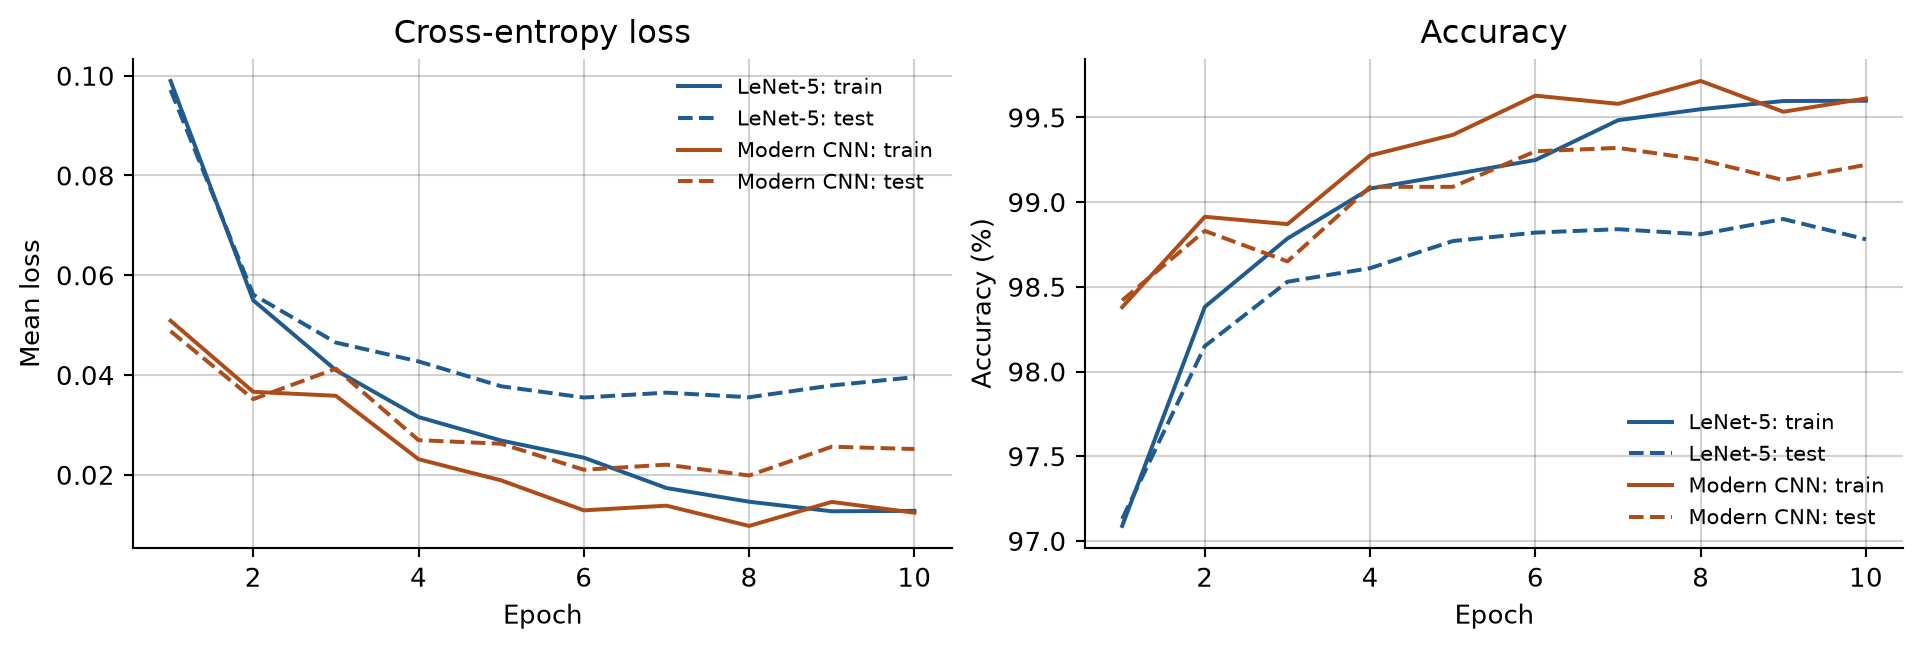

In [13]:
display(Image(filename=str(ROOT/'results'/'figures'/'q2_curves.png')))

*Figure 3. Per-epoch train/test loss and accuracy for both networks under the same training conditions. Solid lines: train; dashed lines: test.*

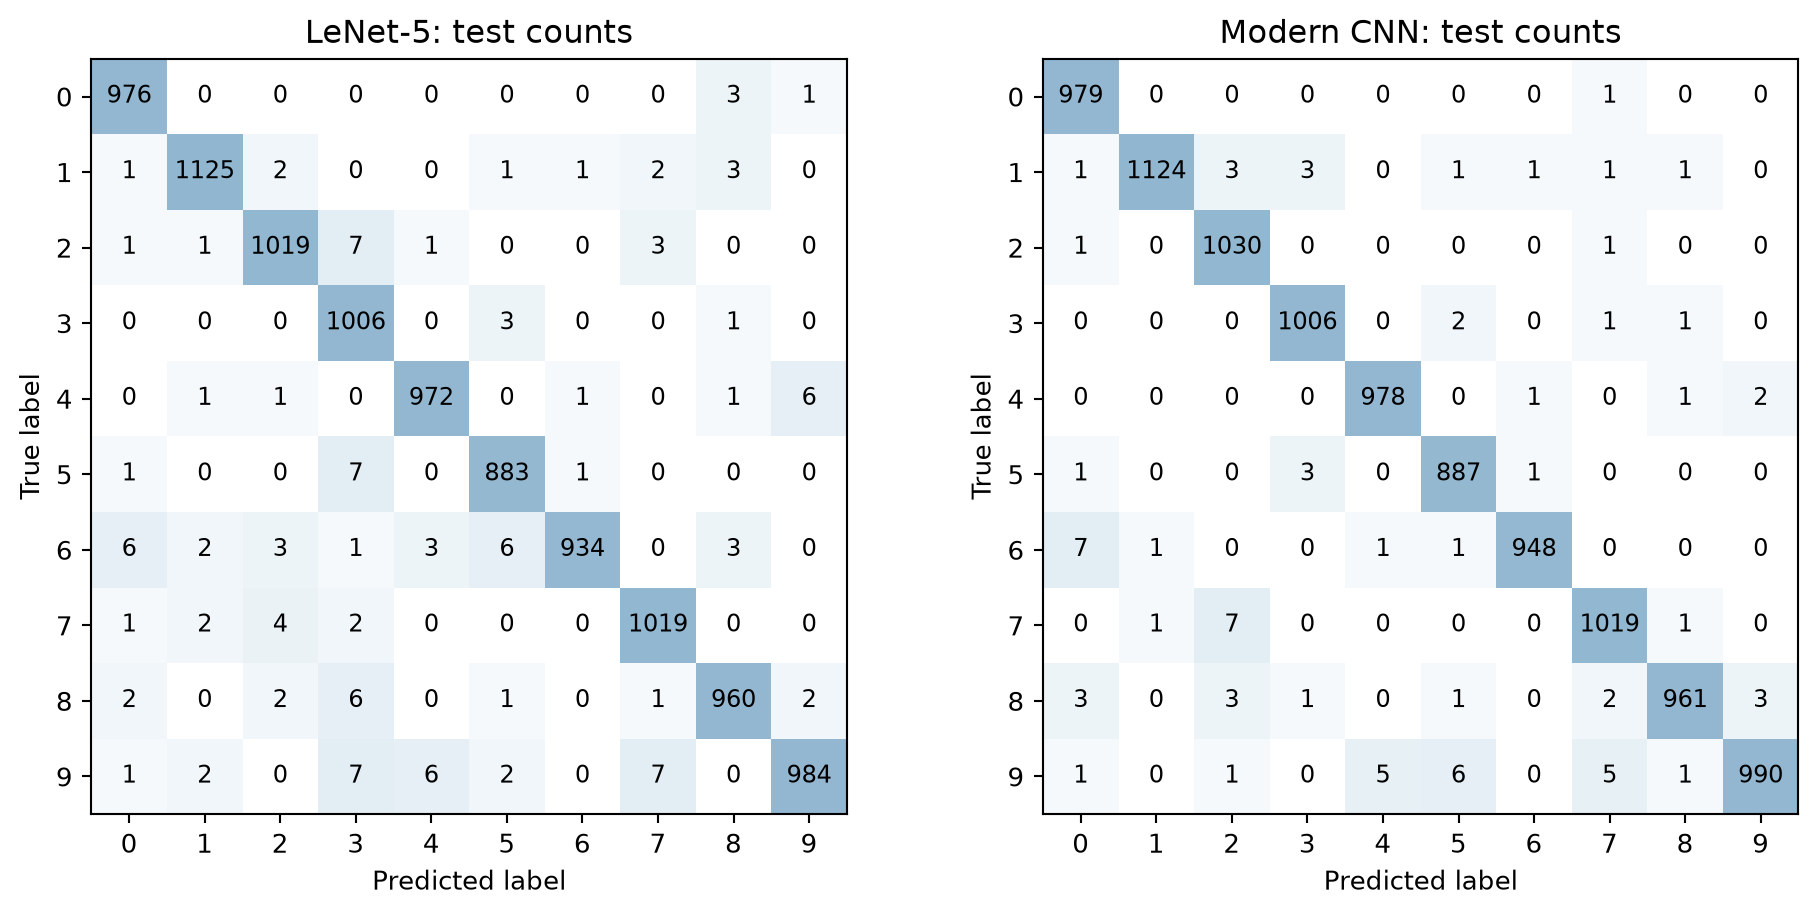

In [14]:
display(Image(filename=str(ROOT/'results'/'figures'/'q2_confusion.png')))

*Figure 4. Separate test confusion matrices. Rows are true labels and columns are predictions; every displayed number is a count. A log(1+count) colour scale makes small off-diagonal errors visible.*

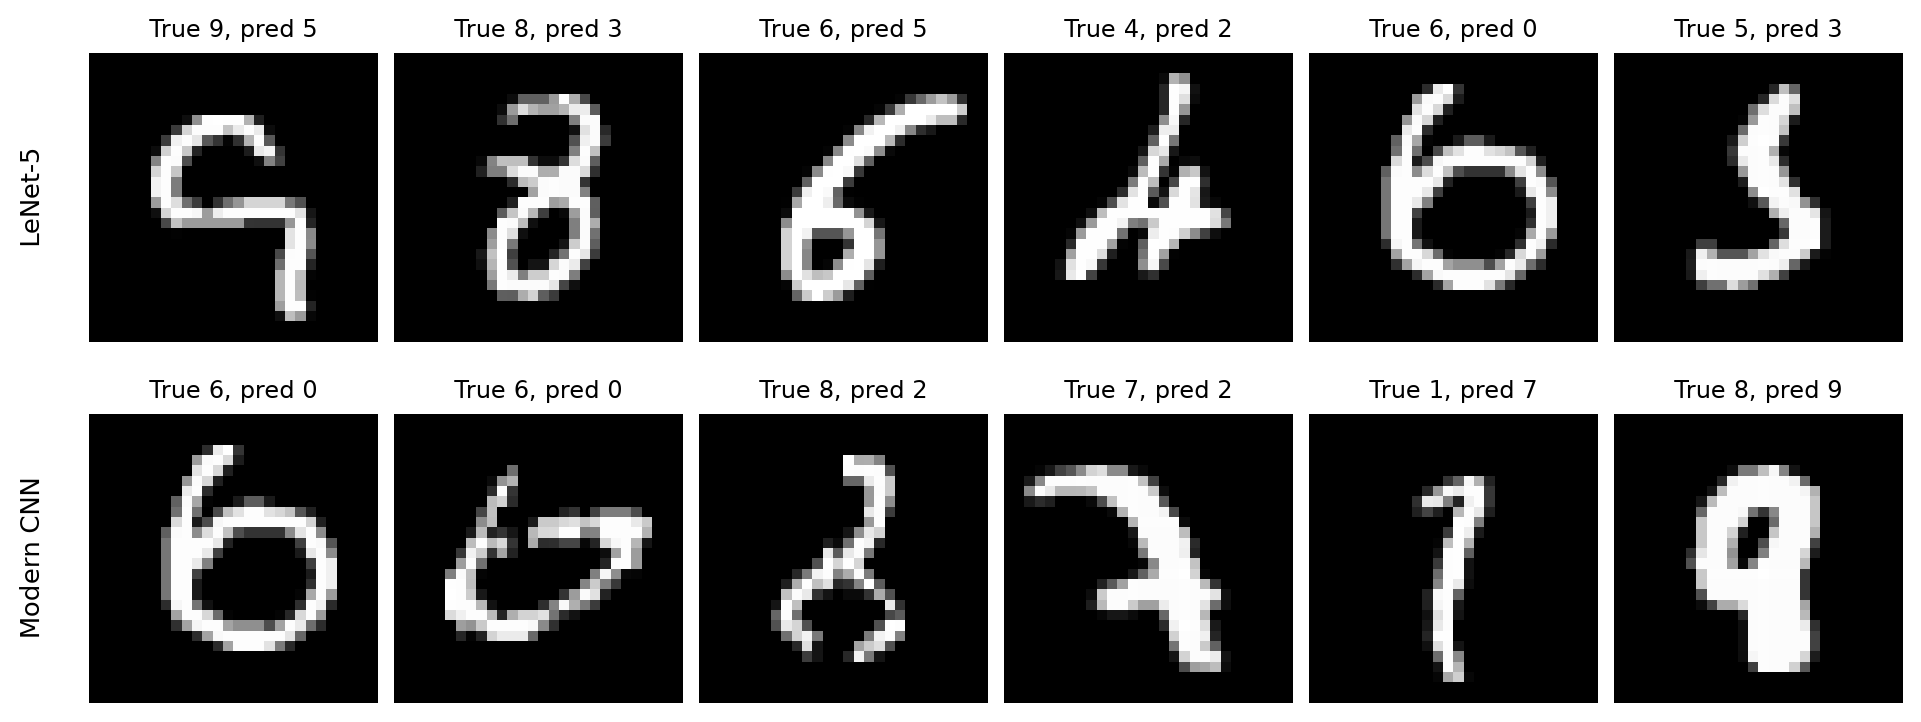

In [15]:
display(Image(filename=str(ROOT/'results'/'figures'/'mnist_errors.png')))

*Figure 5. The first six test errors in dataset order for each model. These examples are illustrative, not a random estimate of error frequency.*

In [16]:
a,b=summary('lenet5'),summary('modern_cnn')
delta=100*(b['test']['accuracy']-a['test']['accuracy'])
display(Markdown(
    f"**Comparison.** Modern CNN minus LeNet-5 is **{delta:+.2f} percentage points** "
    f"in final test accuracy ({b['test']['count']-b['test']['correct']} versus "
    f"{a['test']['count']-a['test']['correct']} errors). "
    f"The train--test gaps are {100*(a['train']['accuracy']-a['test']['accuracy']):.2f} "
    f"points for LeNet-5 and {100*(b['train']['accuracy']-b['test']['accuracy']):.2f} "
    f"for the modern CNN. The modern network uses {b['config']['parameters']:,} "
    f"parameters versus {a['config']['parameters']:,}; training plus evaluation takes "
    f"{b['duration_seconds']:.1f}s versus {a['duration_seconds']:.1f}s in this run. "
    "Batch normalization supports stable deeper optimization; dropout regularizes the "
    "modern model, while convolutional locality benefits both models. Parameter counts "
    "differ, so this compares complete architectures rather than isolating BN or dropout. "
    "The loss curves distinguish confidence changes from changes in the number of "
    "correct classifications. Some poorly formed digits remain ambiguous, as the "
    "error examples show. One seed and ten epochs cannot establish which architecture "
    "is universally best."
))
display(Markdown(
    "LeNet-5's test loss falls to about 0.0355 at epoch 6 and rises to 0.0396 at epoch "
    "10 while training loss continues lower, suggesting mild overfitting. The modern "
    "CNN also fluctuates late in training rather than improving monotonically. Neither "
    "curve is used to replace the prescribed final-epoch checkpoint."
))
import numpy as np
for name in ['lenet5','modern_cnn']:
    cm=np.loadtxt(ROOT/'results'/name/'confusion_matrix.csv',delimiter=',',dtype=int)
    errors=cm.copy();np.fill_diagonal(errors,0)
    pairs=np.dstack(np.unravel_index(np.argsort(errors.ravel())[-3:][::-1],errors.shape))[0]
    print(name, 'largest directed confusions:',
          ', '.join(f'{i} -> {j}: {errors[i,j]}' for i,j in pairs))

**Comparison.** Modern CNN minus LeNet-5 is **+0.44 percentage points** in final test accuracy (78 versus 122 errors). The train--test gaps are 0.82 points for LeNet-5 and 0.39 for the modern CNN. The modern network uses 113,386 parameters versus 61,706; training plus evaluation takes 57.8s versus 12.9s in this run. Batch normalization supports stable deeper optimization; dropout regularizes the modern model, while convolutional locality benefits both models. Parameter counts differ, so this compares complete architectures rather than isolating BN or dropout. The loss curves distinguish confidence changes from changes in the number of correct classifications. Some poorly formed digits remain ambiguous, as the error examples show. One seed and ten epochs cannot establish which architecture is universally best.

LeNet-5's test loss falls to about 0.0355 at epoch 6 and rises to 0.0396 at epoch 10 while training loss continues lower, suggesting mild overfitting. The modern CNN also fluctuates late in training rather than improving monotonically. Neither curve is used to replace the prescribed final-epoch checkpoint.

lenet5 largest directed confusions: 9 -> 7: 7, 9 -> 3: 7, 2 -> 3: 7
modern_cnn largest directed confusions: 7 -> 2: 7, 6 -> 0: 7, 9 -> 5: 6


## 3. Hymenoptera transfer learning with ResNet18

### Data, preprocessing and two adaptation strategies

The tutorial dataset has **244 training images** (123 ants, 121 bees) and **153
validation images** (70 ants, 83 bees). There is **no independent test split**.
Always predicting bees would give 54.25% validation accuracy.

Both experiments start from `ResNet18_Weights.IMAGENET1K_V1`, trained on ImageNet1K.
The original 1000-class head is replaced by a 512→2 linear head. Fine-tuning updates
the entire network. Feature extraction freezes every backbone parameter and all
batch-normalization running statistics; only the new head is trained.

Training uses RandomResizedCrop(224), horizontal flips, and ImageNet normalization
(means 0.485/0.456/0.406, standard deviations 0.229/0.224/0.225). Evaluation uses
Resize(256), CenterCrop(224), and the same normalization. Training accuracy here
is evaluated with deterministic center crops, not random training augmentations.

Both runs use **25 epochs**, batch size **16**, SGD with learning rate **0.001**,
momentum **0.9**, and StepLR(step_size=7, gamma=0.1), based on the official tutorial.
The final epoch is reported instead of selecting the best validation checkpoint.

In [17]:
from torchvision import models
def initialize_resnet(feature_extractor=False):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    if feature_extractor:
        for parameter in model.parameters():
            parameter.requires_grad_(False)
    model.fc = nn.Linear(model.fc.in_features, 2)
    return model

def set_training_mode(model, feature_extractor=False):
    model.train()
    if feature_extractor:
        model.eval()     # Freeze backbone BN running mean and variance too.
        model.fc.train()

In [18]:
if RUN_TRAINING:
    transfer(torch.device('cuda' if torch.cuda.is_available() else 'cpu'))
    refresh_figures('q3')
else:
    print('Using both completed full-data, 25-epoch transfer-learning runs.')
result_table(['resnet18_finetune','resnet18_features'],
             ['ResNet18 fine-tuning','ResNet18 fixed features'],split='validation')
for name in ['resnet18_finetune','resnet18_features']:
    s=summary(name)
    print(name, '| trainable parameters:', s['config']['trainable_parameters'],
          '| validation correct:', s['validation']['correct'], '/', s['validation']['count'],
          '| training + evaluation seconds:', round(s['duration_seconds'],1))

Using both completed full-data, 25-epoch transfer-learning runs.


| Model | Epochs | Train loss | Train accuracy | Validation loss | Validation accuracy |
|---|---:|---:|---:|---:|---:|
| ResNet18 fine-tuning | 25 | 0.0323 | 99.59% | 0.1584 | 94.12% |
| ResNet18 fixed features | 25 | 0.0763 | 97.54% | 0.1129 | 96.08% |

resnet18_finetune | trainable parameters: 11177538 | validation correct: 144 / 153 | training + evaluation seconds: 94.0
resnet18_features | trainable parameters: 1026 | validation correct: 147 / 153 | training + evaluation seconds: 95.0


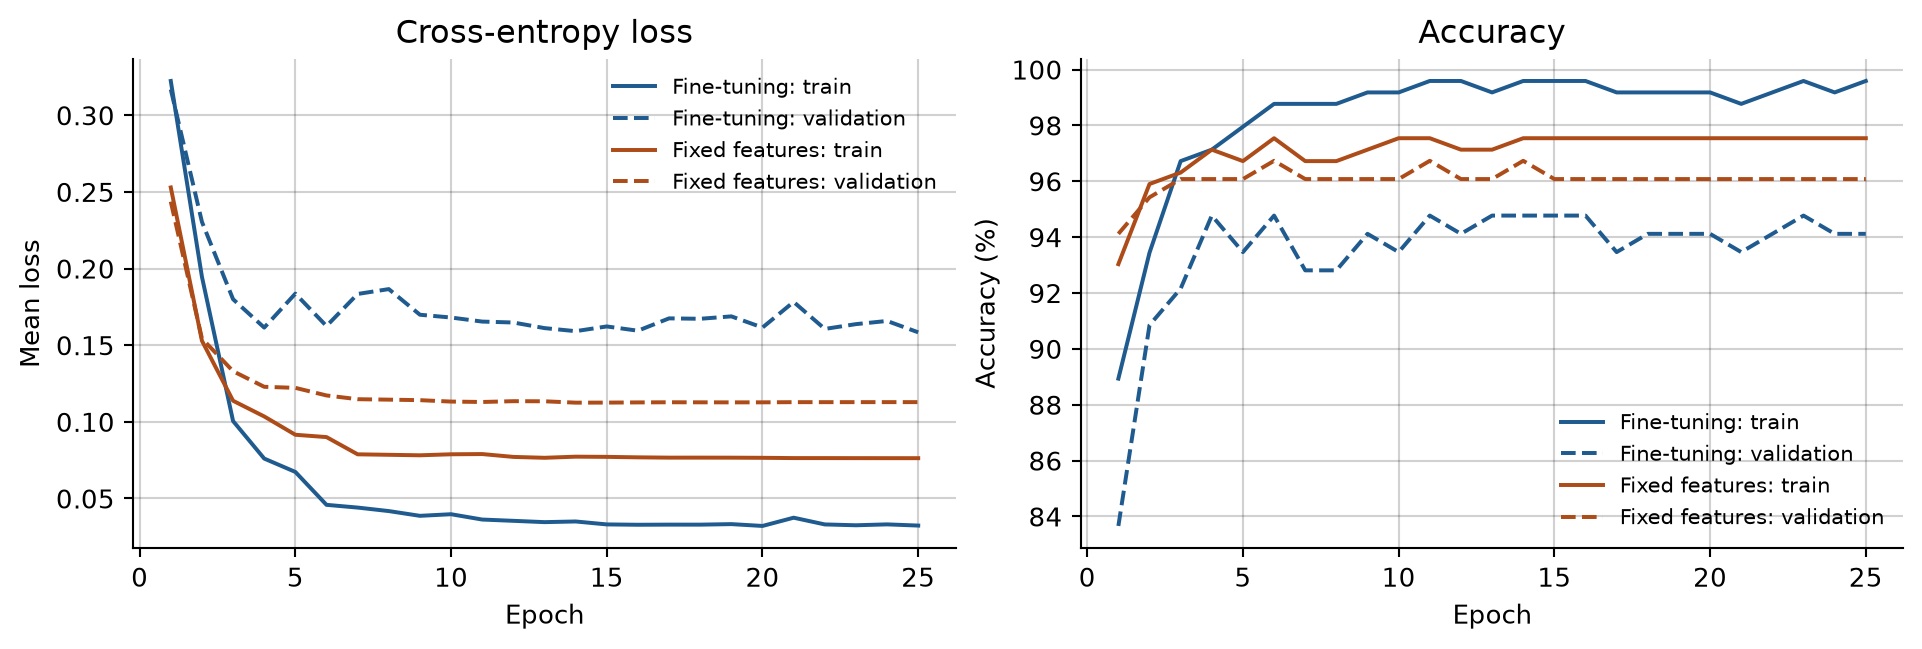

In [19]:
display(Image(filename=str(ROOT/'results'/'figures'/'q3_curves.png')))

*Figure 6. Twenty-five-epoch train/validation learning curves. Scheduled reductions occur after epochs 7, 14, and 21.*

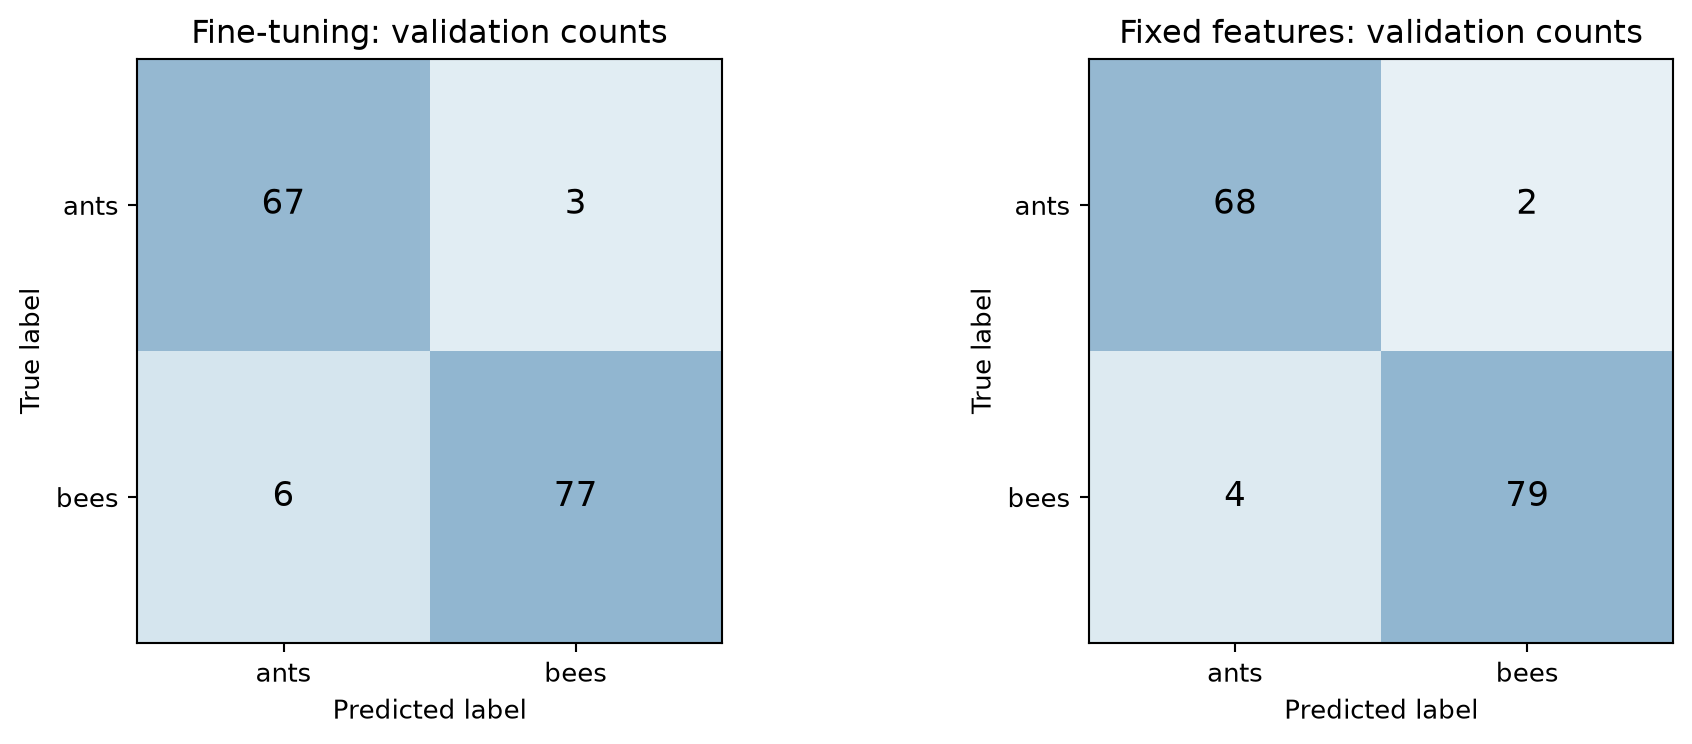

In [20]:
display(Image(filename=str(ROOT/'results'/'figures'/'q3_confusion.png')))

*Figure 7. Validation confusion matrices for fine-tuning and frozen feature extraction. Every matrix contains all 153 held-out images.*

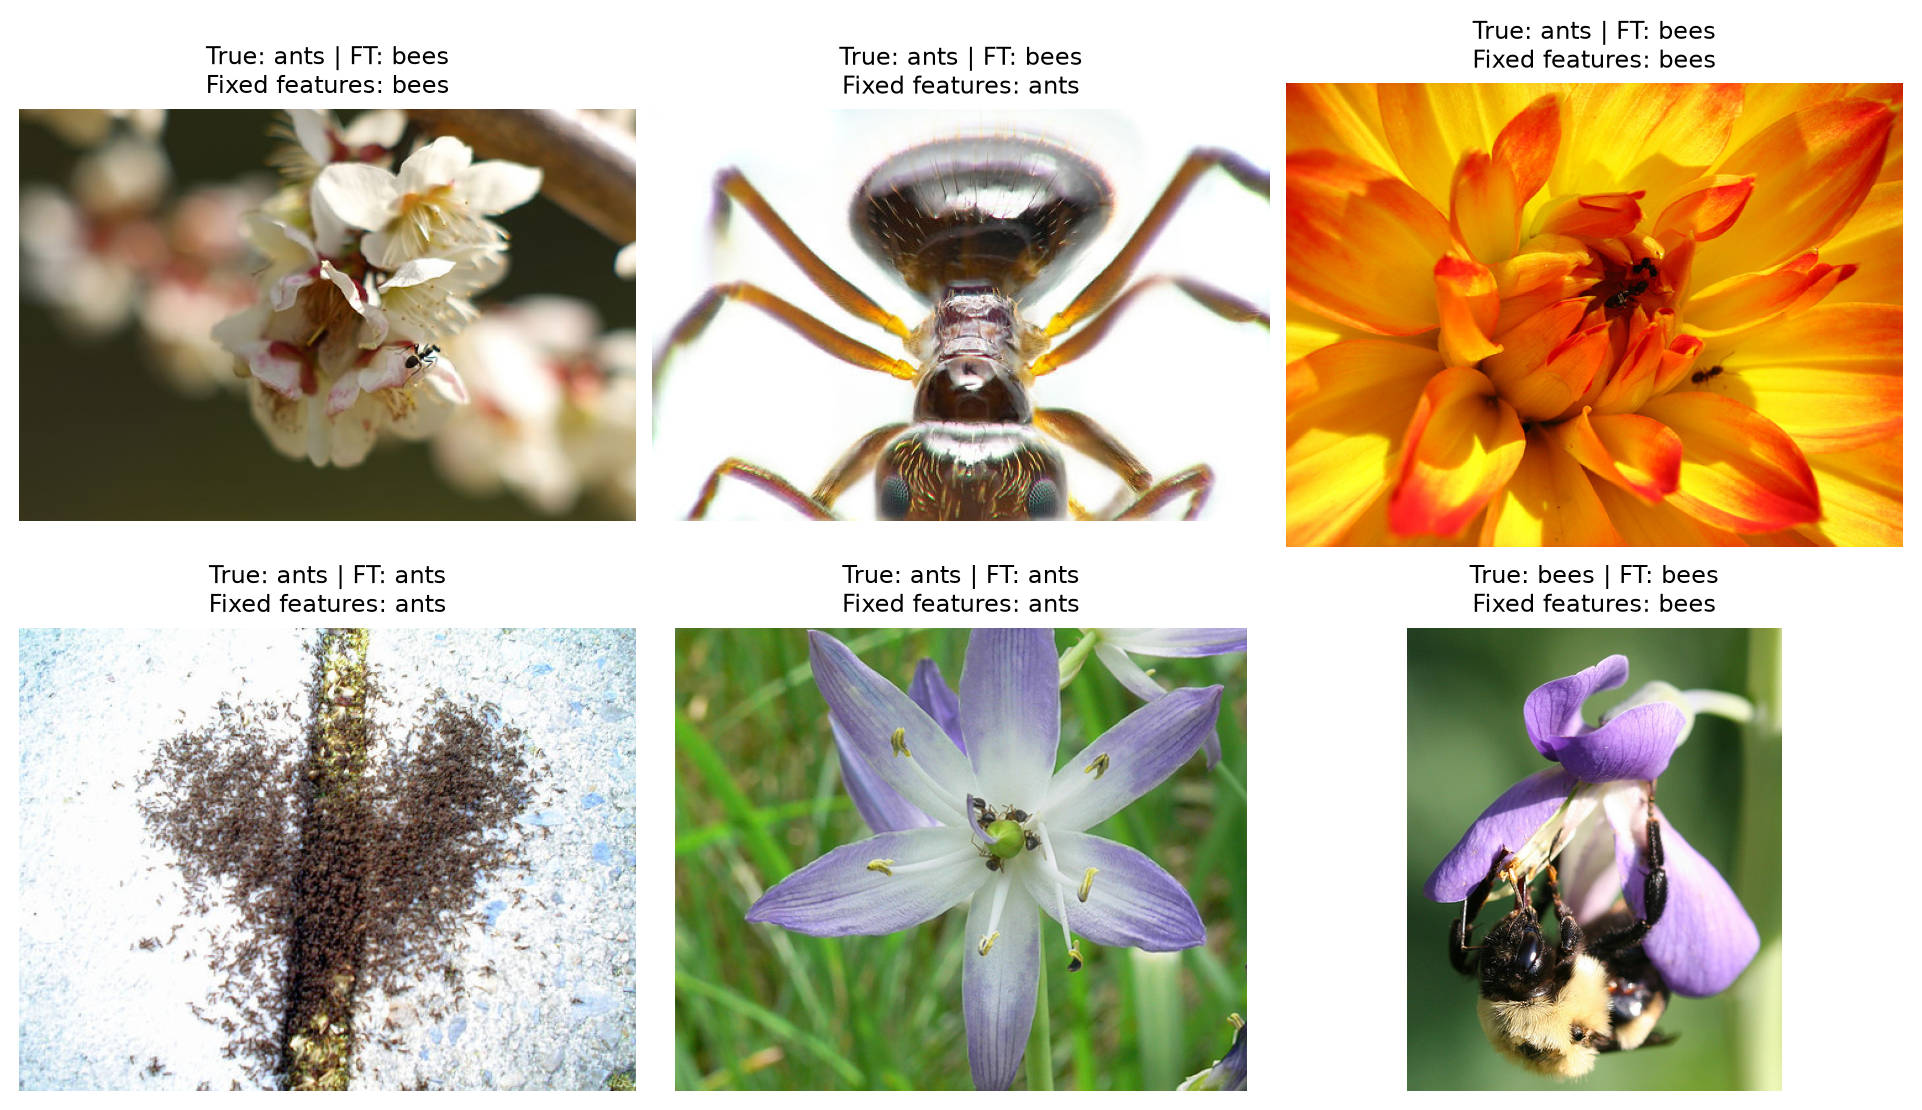

In [21]:
display(Image(filename=str(ROOT/'results'/'figures'/'transfer_examples.png')))

*Figure 8. Actual validation images: the first three disagreements with ground truth from either model, followed by fixed correct examples. FT denotes fine-tuning; original image colours are retained.*

In [22]:
a,b=summary('resnet18_finetune'),summary('resnet18_features')
delta=100*(a['validation']['accuracy']-b['validation']['accuracy'])
display(Markdown(
    f"**Interpretation.** Fine-tuning minus fixed features is **{delta:+.2f} percentage "
    f"points** in final validation accuracy. Fine-tuning gets "
    f"{a['validation']['correct']}/153 correct; the fixed extractor gets "
    f"{b['validation']['correct']}/153. One image changes accuracy by about 0.65 "
    "percentage points on this small split. Fine-tuning adapts visual features but "
    "exposes many more parameters to just 244 training images. A fixed extractor "
    "retains ImageNet representations and reduces the optimized parameter count to "
    "1,026, reducing backward computation and the opportunity to overfit. "
    f"Measured training-plus-evaluation times are {a['duration_seconds']:.1f}s for "
    f"fine-tuning and {b['duration_seconds']:.1f}s for fixed features. These similar "
    "totals include input transforms and full-split evaluation, so this run does "
    "not demonstrate an end-to-end speed advantage for freezing the backbone. "
    "Background context, insect scale, and cropped or partially visible insects can "
    "affect either classifier. These are possible explanations, not causal conclusions "
    "from six visual examples. No independent test split or repeated-seed uncertainty "
    "estimate was supplied, so the comparison is limited to this validation split."
))
for name in ['resnet18_finetune','resnet18_features']:
    cm=np.loadtxt(ROOT/'results'/name/'confusion_matrix.csv',delimiter=',',dtype=int)
    recalls=cm.diagonal()/cm.sum(axis=1)
    print(name, '| ant recall:',f'{100*recalls[0]:.2f}%',
          '| bee recall:',f'{100*recalls[1]:.2f}%',
          '| balanced accuracy:',f'{100*recalls.mean():.2f}%')

**Interpretation.** Fine-tuning minus fixed features is **-1.96 percentage points** in final validation accuracy. Fine-tuning gets 144/153 correct; the fixed extractor gets 147/153. One image changes accuracy by about 0.65 percentage points on this small split. Fine-tuning adapts visual features but exposes many more parameters to just 244 training images. A fixed extractor retains ImageNet representations and reduces the optimized parameter count to 1,026, reducing backward computation and the opportunity to overfit. Measured training-plus-evaluation times are 94.0s for fine-tuning and 95.0s for fixed features. These similar totals include input transforms and full-split evaluation, so this run does not demonstrate an end-to-end speed advantage for freezing the backbone. Background context, insect scale, and cropped or partially visible insects can affect either classifier. These are possible explanations, not causal conclusions from six visual examples. No independent test split or repeated-seed uncertainty estimate was supplied, so the comparison is limited to this validation split.

resnet18_finetune | ant recall: 95.71% | bee recall: 92.77% | balanced accuracy: 94.24%
resnet18_features | ant recall: 97.14% | bee recall: 95.18% | balanced accuracy: 96.16%


## 4. Reproducibility and verification

The executed notebook loads the saved full-training results by default, explicitly
printing this choice. Setting `RUN_TRAINING=True` reruns the actual experiment
functions. Training code is in `src/models.py` and `src/experiments.py`; epoch CSVs,
prediction arrays, count matrices, input SHA-256 hashes, runtime versions, seeds,
checkpoint hashes and figures are retained in the repository. The saved checkpoints
allow independent inference without retraining.

The manual-gradient test checks all four analytic gradients against float64 autograd,
including repeated class labels. A large-logit case checks loss stability and an SGD
step. Other tests verify the required model shapes/layer counts and that the fixed
extractor keeps BN statistics unchanged while the classification head receives gradients.
The held-out predictions are also regenerated by independently reloading each saved
checkpoint and compared with the archived prediction arrays. Confusion-matrix totals,
diagonal accuracies, epoch counts, summaries and checkpoint hashes are cross-checked.

Reproduce from the repository root:

```bash
python -m pip install -r requirements.txt
python -m pytest tests -q
python -m src.experiments --task all
python scripts/verify_results.py
python scripts/verify_checkpoints.py
python scripts/make_figures.py
python scripts/build_notebook.py
python scripts/export_pdf.py
```

The notebook PDF is generated through LaTeX, with black document text and rules,
a compact university heading on the first content page, and original-colour raster
images. No separate cover is used.

### References

1. Ranga Rodrigo. *EN3160 Assignment 3 on Neural Networks*, October 9, 2026. Supplied brief.
2. PyTorch. [Transfer Learning for Computer Vision Tutorial](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html).
3. [CIFAR-10 dataset](https://www.cs.toronto.edu/~kriz/cifar.html).
4. Torchvision. [MNIST dataset](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html).
5. Torchvision. [ResNet18 and ImageNet1K weights](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html).

The preprocessing and learning-rate schedule in Question 3 follow Reference 2;
batch size 16, final-epoch reporting, and frozen BN buffers are disclosed adaptations.